# 02. Análise exploratória do dataset de contratos

Este notebook lê o dataset produzido por `01_dataset_exploratorio_novas_fontes.ipynb` e apresenta uma visão geral com gráficos clássicos e verificações simples.

Arquivos aceitos:

- `data/processed/dataset_exploratorio_contratos.parquet`
- `data/processed/dataset_exploratorio_contratos.csv`


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


## 1. Localização do projeto e carregamento

In [2]:
def find_project_root() -> Path:
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "data" / "processed").exists():
            return candidate
    return current.parent if current.name == "notebooks" else current


PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

PARQUET_PATH = PROCESSED_DIR / "dataset_exploratorio_contratos.parquet"
CSV_PATH = PROCESSED_DIR / "dataset_modelagem_obras_snapshots.csv"

if PARQUET_PATH.exists():
    df = pd.read_parquet(PARQUET_PATH)
    source_path = PARQUET_PATH
elif CSV_PATH.exists():
    df = pd.read_csv(CSV_PATH, parse_dates=["data_corte"], low_memory=False)
    source_path = CSV_PATH
else:
    raise FileNotFoundError(
        "Dataset não encontrado. Execute primeiro o notebook "
        "01_dataset_exploratorio_novas_fontes.ipynb."
    )

for column in [
    "data_corte", "Data_assinatura_contrato", "Data_conclusao_contrato",
    "Data_conclusao", "Data_OS", "Data_Paralisacao", "Data_Prev_Retomada",
    "data_termino_vigente"
]:
    if column in df.columns:
        df[column] = pd.to_datetime(df[column], errors="coerce")

print("Arquivo:", source_path)
print("Linhas:", f"{len(df):,}")
print("Colunas:", df.shape[1])
print("Contratos:", df["id_contrato"].nunique())
print("Período:", df["data_corte"].min(), "a", df["data_corte"].max())


Arquivo: C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\data\processed\dataset_modelagem_obras_snapshots.csv
Linhas: 1,435
Colunas: 43
Contratos: 78
Período: 2018-03-22 00:00:00 a 2026-09-29 00:00:00


## 2. Amostra e estrutura

In [3]:
display(df.head())
df.info()


,id_contrato,data_corte,numero_contrato,classificacao_contrato,id_fornecedor,valor_total_contrato,prazo_original_dias,data_os,data_termino_original,data_termino_vigente_corte,dias_desde_os,dias_restantes_prazo_vigente,prazo_vigente_total_dias,pct_prazo_consumido,qtd_aditivos_prazo,dias_aditados_acumulados,dias_desde_ultimo_aditivo_prazo,qtd_aditivos_valor,dias_desde_ultimo_aditivo_valor,qtd_parcelas_previstas_ate_corte,qtd_parcelas_concluidas_ate_corte,pct_parcelas_concluidas_vs_previstas,atraso_medio_parcelas_dias,atraso_mediano_parcelas_dias,atraso_maximo_parcelas_dias,qtd_parcelas_atrasadas,pct_parcelas_atrasadas,atraso_medio_parcelas_90d,qtd_parcelas_atrasadas_90d,qtd_liberacoes,valor_liberado_acumulado,valor_liberado_90d,atraso_medio_liberacao_dias,atraso_maximo_liberacao_dias,pct_financeiro_liberado,gap_prazo_financeiro,status_final_controle,data_conclusao_controle,data_termino_vigente_final_controle,target_dias_atraso,target_atraso,faixa_antecedencia,flag_apto_treino
0,11,2019-07-24,160/2018,Reforma Parcial,35,"276,770.81",150,2019-07-24,2019-12-21,2019-12-21,0,150,150,0.00,0,0,NaN,1,23.00,0,0,NaN,NaN,NaN,NaN,0,NaN,NaN,0,0,0.00,0.00,NaN,NaN,0.00,0.00,CONCLUÍDO,2020-01-15,2019-12-21,25.00,1.00,90-179d,1
1,11,2019-07-31,160/2018,Reforma Parcial,35,"276,770.81",150,2019-07-24,2019-12-21,2019-12-21,7,143,150,0.05,0,0,NaN,1,30.00,0,0,NaN,NaN,NaN,NaN,0,NaN,NaN,0,0,0.00,0.00,NaN,NaN,0.00,0.05,CONCLUÍDO,2020-01-15,2019-12-21,25.00,1.00,90-179d,1
2,11,2019-08-31,160/2018,Reforma Parcial,35,"276,770.81",150,2019-07-24,2019-12-21,2019-12-21,38,112,150,0.25,0,0,NaN,1,61.00,1,1,1.00,-3.00,-3.00,-3.00,0,0.00,-3.00,0,1,"19,716.18","19,716.18",0.00,0.00,0.07,0.18,CONCLUÍDO,2020-01-15,2019-12-21,25.00,1.00,90-179d,1
3,11,2019-09-30,160/2018,Reforma Parcial,35,"276,770.81",150,2019-07-24,2019-12-21,2019-12-21,68,82,150,0.45,0,0,NaN,1,91.00,2,3,1.50,-14.33,-12.00,-3.00,0,0.00,-14.33,0,3,"59,228.56","59,228.56",0.00,0.00,0.21,0.24,CONCLUÍDO,2020-01-15,2019-12-21,25.00,1.00,30-89d,1
4,11,2019-10-31,160/2018,Reforma Parcial,35,"276,770.81",150,2019-07-24,2019-12-21,2019-12-21,99,51,150,0.66,0,0,NaN,1,122.00,3,3,1.00,-14.33,-12.00,-3.00,0,0.00,-14.33,0,3,"59,228.56","59,228.56",0.00,0.00,0.21,0.45,CONCLUÍDO,2020-01-15,2019-12-21,25.00,1.00,30-89d,1


<class 'pandas.DataFrame'>
RangeIndex: 1435 entries, 0 to 1434
Data columns (total 43 columns):
 #   Column                                Non-Null Count  Dtype         
---  ------                                --------------  -----         
 0   id_contrato                           1435 non-null   int64         
 1   data_corte                            1435 non-null   datetime64[us]
 2   numero_contrato                       1435 non-null   str           
 3   classificacao_contrato                1435 non-null   str           
 4   id_fornecedor                         1435 non-null   int64         
 5   valor_total_contrato                  1435 non-null   float64       
 6   prazo_original_dias                   1435 non-null   int64         
 7   data_os                               1435 non-null   str           
 8   data_termino_original                 1435 non-null   str           
 9   data_termino_vigente_corte            1435 non-null   str           
 10  dias_desde_

In [4]:
resumo_numerico = df.describe(include=[np.number]).T
resumo_numerico


,count,mean,std,min,25%,50%,75%,max
id_contrato,"1,435.00",181.90,120.61,11.00,57.00,174.00,271.00,418.00
id_fornecedor,"1,435.00",89.11,51.67,1.00,45.00,89.00,116.00,197.00
valor_total_contrato,"1,435.00","8,182,194.63","8,272,501.99","74,431.77","721,943.23","3,218,369.52","17,228,423.27","32,809,985.80"
prazo_original_dias,"1,435.00",506.76,357.24,60.00,150.00,420.00,780.00,"1,260.00"
dias_desde_os,"1,435.00",403.05,426.39,0.00,109.00,270.00,554.00,"2,577.00"
dias_restantes_prazo_vigente,"1,435.00",187.96,348.13,-734.00,-9.00,84.00,378.00,"1,260.00"
prazo_vigente_total_dias,"1,435.00",591.01,418.99,60.00,180.00,541.00,960.00,"1,843.00"
pct_prazo_consumido,"1,435.00",0.81,0.82,0.00,0.29,0.73,1.03,7.33
qtd_aditivos_prazo,"1,435.00",1.44,2.80,0.00,0.00,0.00,2.00,20.00
dias_aditados_acumulados,"1,435.00",84.41,161.41,0.00,0.00,0.00,90.00,811.00


## 3. Qualidade dos dados

In [5]:
qualidade = pd.DataFrame({
    "coluna": df.columns,
    "tipo": df.dtypes.astype(str).values,
    "nulos": df.isna().sum().values,
    "percentual_nulos": (df.isna().mean().values * 100).round(2),
    "valores_distintos": [df[column].nunique(dropna=True) for column in df.columns],
}).sort_values("percentual_nulos", ascending=False)

qualidade.head(25)


,coluna,tipo,nulos,percentual_nulos,valores_distintos
16,dias_desde_ultimo_aditivo_prazo,float64,762,53.10,321
18,dias_desde_ultimo_aditivo_valor,float64,637,44.39,314
27,atraso_medio_parcelas_90d,float64,394,27.46,601
40,target_atraso,float64,342,23.83,2
39,target_dias_atraso,float64,342,23.83,40
37,data_conclusao_controle,str,342,23.83,59
38,data_termino_vigente_final_controle,str,342,23.83,58
32,atraso_medio_liberacao_dias,float64,238,16.59,289
33,atraso_maximo_liberacao_dias,float64,238,16.59,75
23,atraso_mediano_parcelas_dias,float64,210,14.63,173


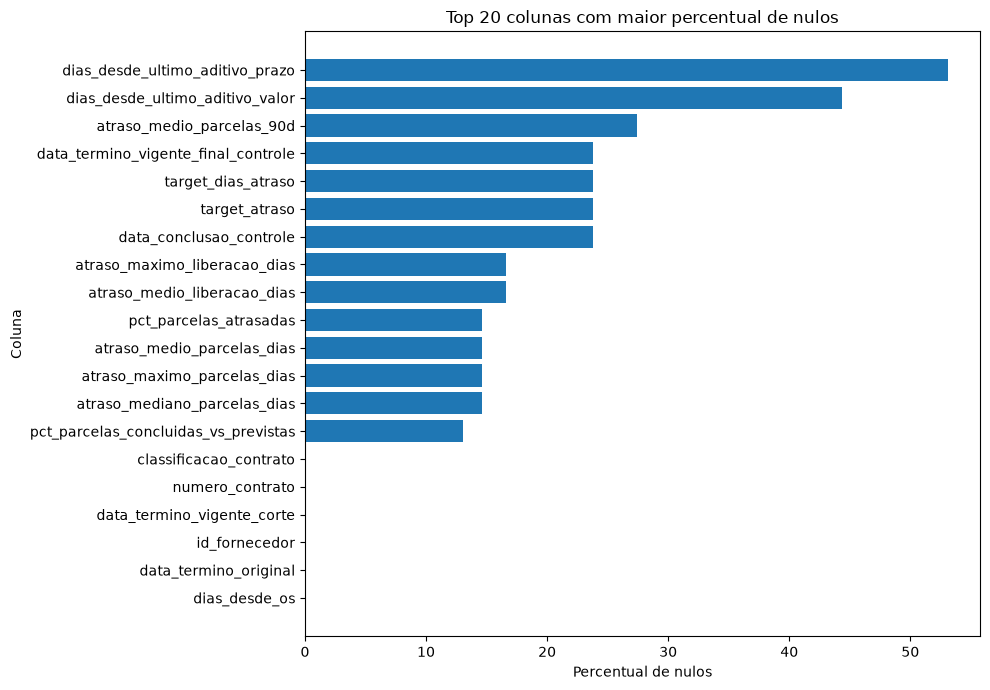

In [6]:
top_nulos = qualidade.head(20).sort_values("percentual_nulos")

plt.figure(figsize=(10, 7))
plt.barh(top_nulos["coluna"], top_nulos["percentual_nulos"])
plt.title("Top 20 colunas com maior percentual de nulos")
plt.xlabel("Percentual de nulos")
plt.ylabel("Coluna")
plt.tight_layout()
plt.show()


In [7]:
print("Duplicidades completas:", int(df.duplicated().sum()))
print(
    "Duplicidades por contrato e data de corte:",
    int(df.duplicated(["id_contrato", "data_corte"]).sum())
)


Duplicidades completas: 0
Duplicidades por contrato e data de corte: 0


## 4. Visão cadastral dos contratos

Para evitar contar o mesmo contrato várias vezes, esta seção usa apenas o snapshot mais recente de cada contrato.

In [8]:
latest = (
    df.sort_values(["id_contrato", "data_corte"])
    .groupby("id_contrato", as_index=False)
    .tail(1)
    .copy()
)

print("Contratos no recorte mais recente:", len(latest))
latest.head()


Contratos no recorte mais recente: 78


,id_contrato,data_corte,numero_contrato,classificacao_contrato,id_fornecedor,valor_total_contrato,prazo_original_dias,data_os,data_termino_original,data_termino_vigente_corte,dias_desde_os,dias_restantes_prazo_vigente,prazo_vigente_total_dias,pct_prazo_consumido,qtd_aditivos_prazo,dias_aditados_acumulados,dias_desde_ultimo_aditivo_prazo,qtd_aditivos_valor,dias_desde_ultimo_aditivo_valor,qtd_parcelas_previstas_ate_corte,qtd_parcelas_concluidas_ate_corte,pct_parcelas_concluidas_vs_previstas,atraso_medio_parcelas_dias,atraso_mediano_parcelas_dias,atraso_maximo_parcelas_dias,qtd_parcelas_atrasadas,pct_parcelas_atrasadas,atraso_medio_parcelas_90d,qtd_parcelas_atrasadas_90d,qtd_liberacoes,valor_liberado_acumulado,valor_liberado_90d,atraso_medio_liberacao_dias,atraso_maximo_liberacao_dias,pct_financeiro_liberado,gap_prazo_financeiro,status_final_controle,data_conclusao_controle,data_termino_vigente_final_controle,target_dias_atraso,target_atraso,faixa_antecedencia,flag_apto_treino
7,11,2020-01-15,160/2018,Reforma Parcial,35,"276,770.81",150,2019-07-24,2019-12-21,2019-12-21,175,-25,150,1.17,0,0,NaN,2,33.00,10,7,0.70,-2.14,-3.00,25.00,2,0.29,7.00,2,5,"292,770.62","233,542.06",0.00,0.00,1.06,0.11,CONCLUÍDO,2020-01-15,2019-12-21,25.00,1.00,<30d,0
17,12,2018-11-06,32/2018,Reforma Parcial,36,"123,157.43",90,2018-03-22,2018-06-20,2018-06-20,229,-139,90,2.54,0,0,NaN,0,NaN,0,0,NaN,NaN,NaN,NaN,0,NaN,NaN,0,0,0.00,0.00,NaN,NaN,0.00,2.54,CONCLUÍDO,2018-11-06,2018-06-20,139.00,1.00,<30d,0
24,18,2020-02-08,145/2019,Reforma Parcial,39,"286,883.22",120,2019-09-11,2020-01-09,2020-02-08,150,0,150,1.00,1,30,0.00,1,8.00,8,8,1.00,-6.00,0.00,0.00,0,0.00,-7.17,0,4,"244,449.09","207,767.64",0.00,0.00,0.85,0.15,CONCLUÍDO,2020-02-08,2020-02-08,0.00,0.00,<30d,0
111,28,2025-07-03,50/2018,Construção,40,"17,228,423.27",1080,2018-06-13,2021-05-28,2023-06-30,2577,-734,1843,1.40,7,763,770.00,5,"1,056.00",96,92,0.96,10.55,13.50,279.00,62,0.67,NaN,0,92,"16,502,696.69",0.00,22.79,181.00,0.96,0.44,RESCINDIDO,2025-07-03,2023-06-30,734.00,1.00,<30d,0
131,29,2020-07-06,210/2018,Reforma Parcial e Ampliação,41,"672,041.16",240,2019-01-29,2019-09-26,2020-03-22,524,-106,418,1.25,4,178,125.00,5,137.00,38,38,1.00,15.18,12.00,164.00,23,0.61,120.50,4,34,"690,709.54",0.00,1.18,21.00,1.03,0.23,CONCLUÍDO,2020-07-06,2020-03-22,106.00,1.00,<30d,0


In [9]:
def plot_counts(series, title, top=15):
    counts = series.fillna("Não informado").value_counts().head(top).sort_values()
    plt.figure(figsize=(10, 6))
    plt.barh(counts.index.astype(str), counts.values)
    plt.title(title)
    plt.xlabel("Quantidade de contratos")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()


plot_counts(latest["status_contrato"], "Contratos por status")


KeyError: 'status_contrato'

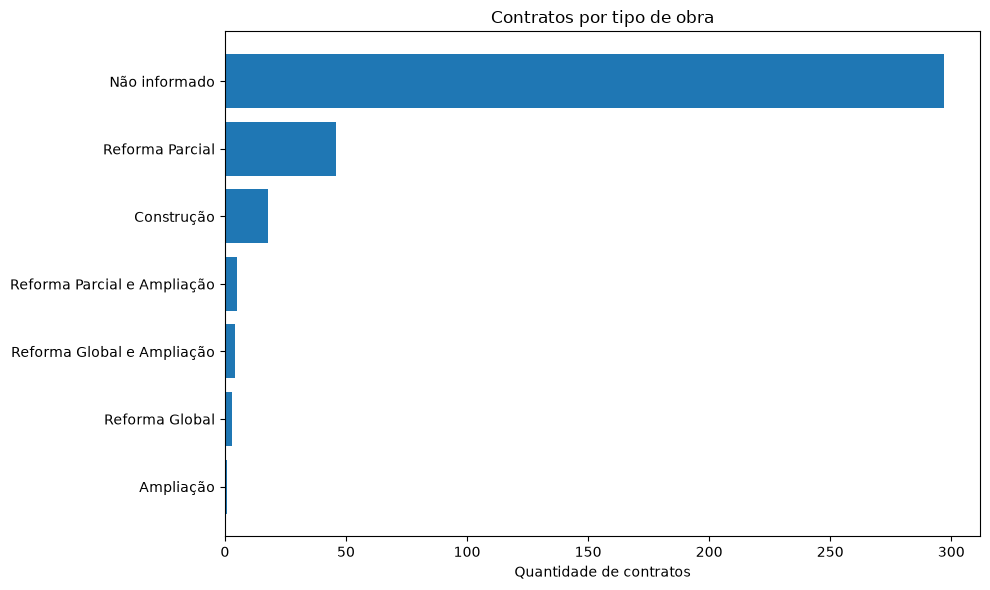

In [ ]:
plot_counts(latest["tipo_obra"], "Contratos por tipo de obra")


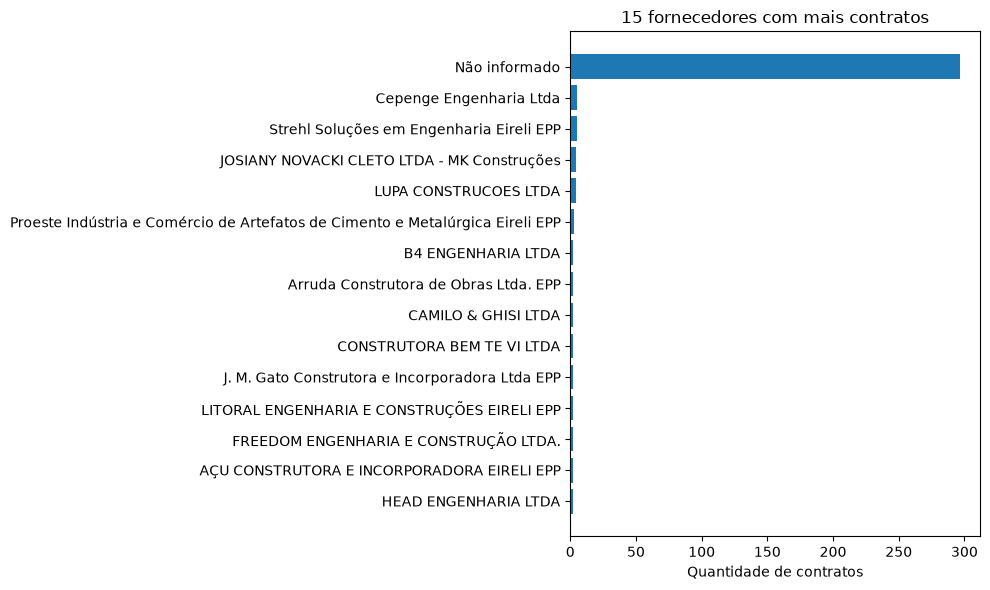

In [ ]:
if "nome_fornecedor" in latest.columns:
    plot_counts(latest["nome_fornecedor"], "15 fornecedores com mais contratos", top=15)


## 5. Distribuição dos valores e prazos

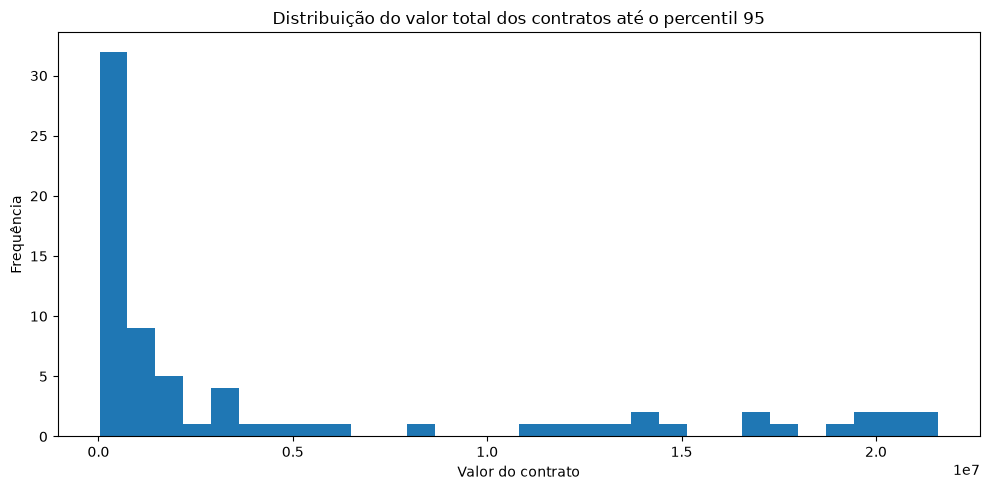

In [ ]:
def histogram(series, title, xlabel, bins=30, upper_quantile=None):
    values = pd.to_numeric(series, errors="coerce").dropna()
    if upper_quantile is not None and not values.empty:
        values = values[values <= values.quantile(upper_quantile)]
    plt.figure(figsize=(10, 5))
    plt.hist(values, bins=bins)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Frequência")
    plt.tight_layout()
    plt.show()


histogram(
    latest["valor_total_contrato"],
    "Distribuição do valor total dos contratos até o percentil 95",
    "Valor do contrato",
    upper_quantile=0.95,
)


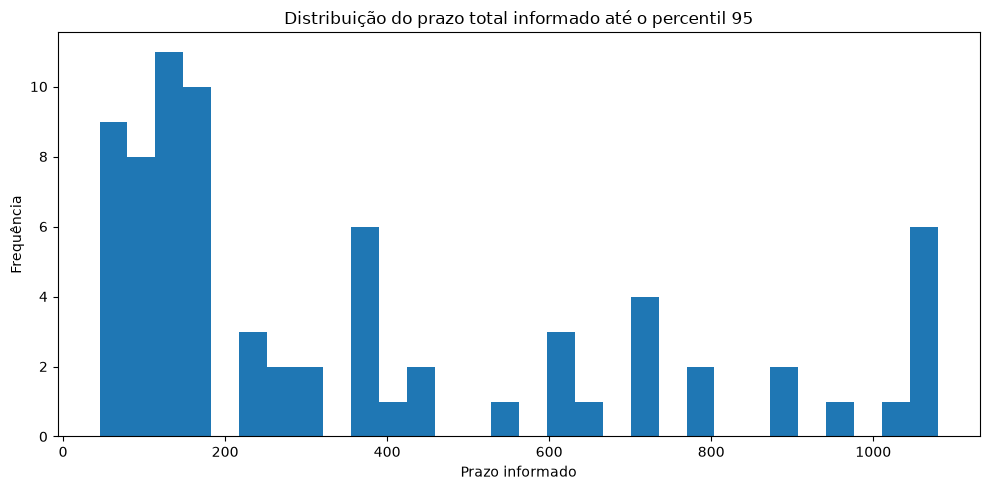

In [ ]:
histogram(
    latest["prazo_total_informado"],
    "Distribuição do prazo total informado até o percentil 95",
    "Prazo informado",
    upper_quantile=0.95,
)


## 6. Parcelas e execução financeira

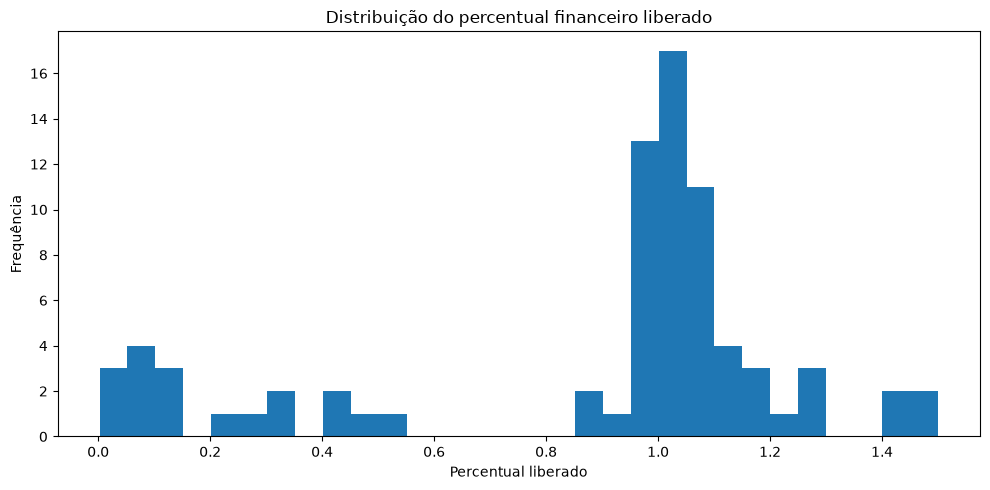

In [ ]:
histogram(
    latest["percentual_financeiro_liberado"].clip(lower=0, upper=1.5),
    "Distribuição do percentual financeiro liberado",
    "Percentual liberado",
    bins=30,
)


In [ ]:
financeiro = latest[[
    column for column in [
        "id_contrato", "valor_total_contrato", "valor_liberado_acumulado",
        "percentual_financeiro_liberado", "qtd_parcelas_acumulado",
        "qtd_parcelas_liberadas_acumulado"
    ] if column in latest.columns
]].copy()

financeiro.sort_values("percentual_financeiro_liberado", ascending=False).head(20)


,id_contrato,valor_total_contrato,valor_liberado_acumulado,percentual_financeiro_liberado,qtd_parcelas_acumulado,qtd_parcelas_liberadas_acumulado
298,49,"135,821.26","462,275.23",3.40,5.00,5.00
6551,288,"257,760.11","377,127.79",1.46,3.00,3.00
445,60,"3,213,805.64","4,547,358.79",1.41,33.00,33.00
12,11,"276,770.81","390,675.38",1.41,8.00,8.00
6993,317,"856,839.36","1,091,504.82",1.27,22.00,22.00
2985,153,"11,465,196.19","14,452,648.82",1.26,64.00,64.00
385,57,"1,100,000.00","1,375,788.64",1.25,43.00,43.00
415,59,"1,646,374.66","1,989,023.15",1.21,23.00,23.00
5386,254,"8,188,600.72","9,719,134.58",1.19,32.00,32.00
159,31,"376,739.26","437,195.07",1.16,8.00,8.00


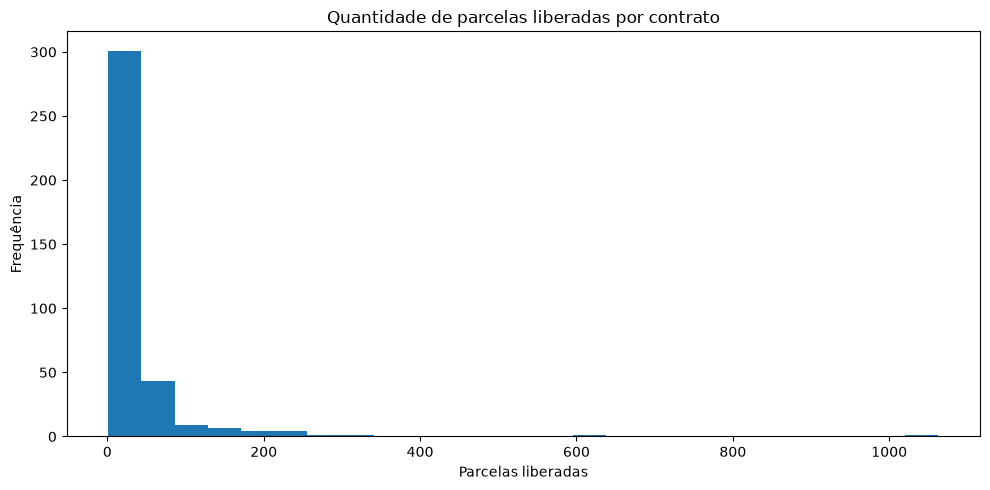

In [ ]:
if "qtd_parcelas_liberadas_acumulado" in latest.columns:
    histogram(
        latest["qtd_parcelas_liberadas_acumulado"],
        "Quantidade de parcelas liberadas por contrato",
        "Parcelas liberadas",
        bins=25,
    )


## 7. Aditivos de prazo e valor

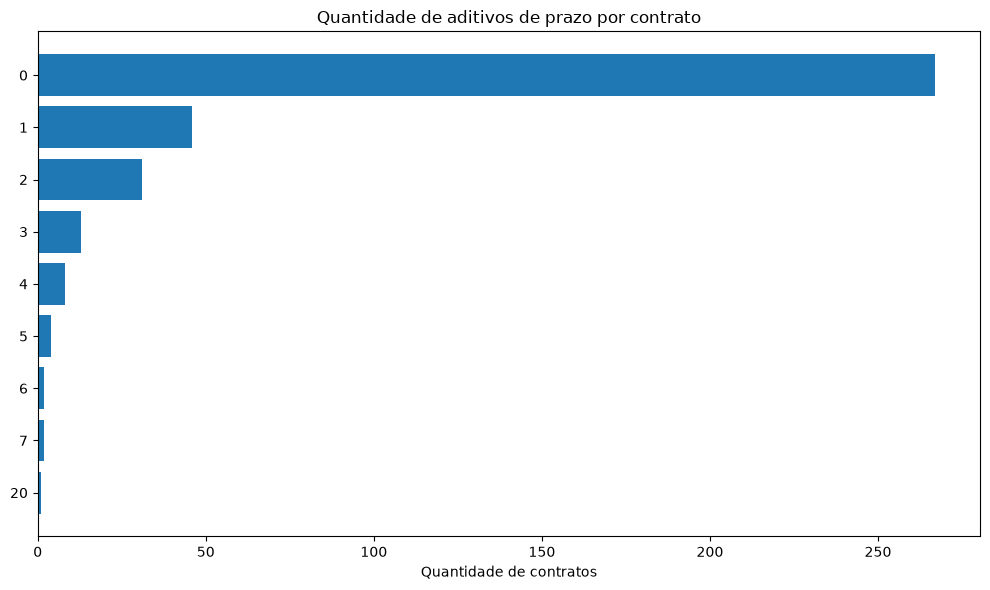

In [ ]:
if "qtd_aditivos_prazo_acumulado" in latest.columns:
    plot_counts(
        latest["qtd_aditivos_prazo_acumulado"].fillna(0).astype(int),
        "Quantidade de aditivos de prazo por contrato",
        top=15,
    )


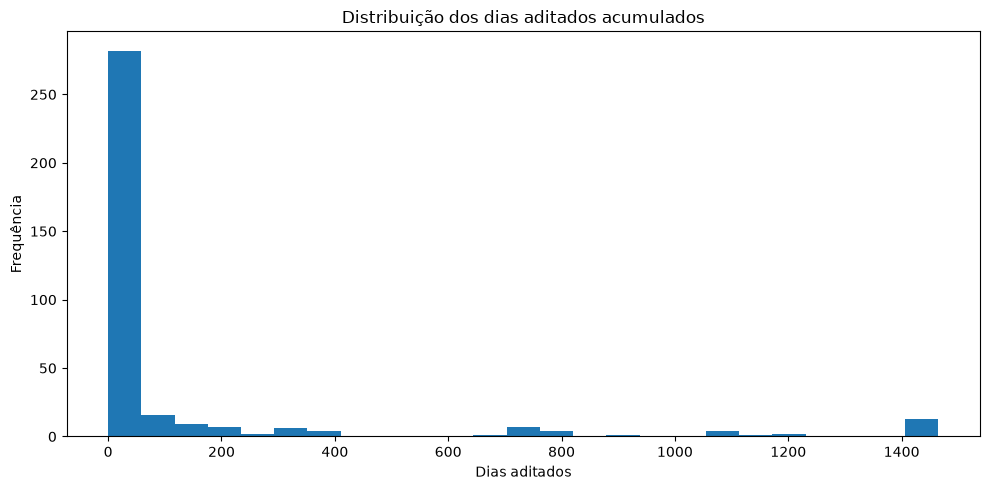

In [ ]:
if "dias_aditados_acumulado" in latest.columns:
    histogram(
        latest["dias_aditados_acumulado"].fillna(0),
        "Distribuição dos dias aditados acumulados",
        "Dias aditados",
        bins=25,
        upper_quantile=0.95,
    )


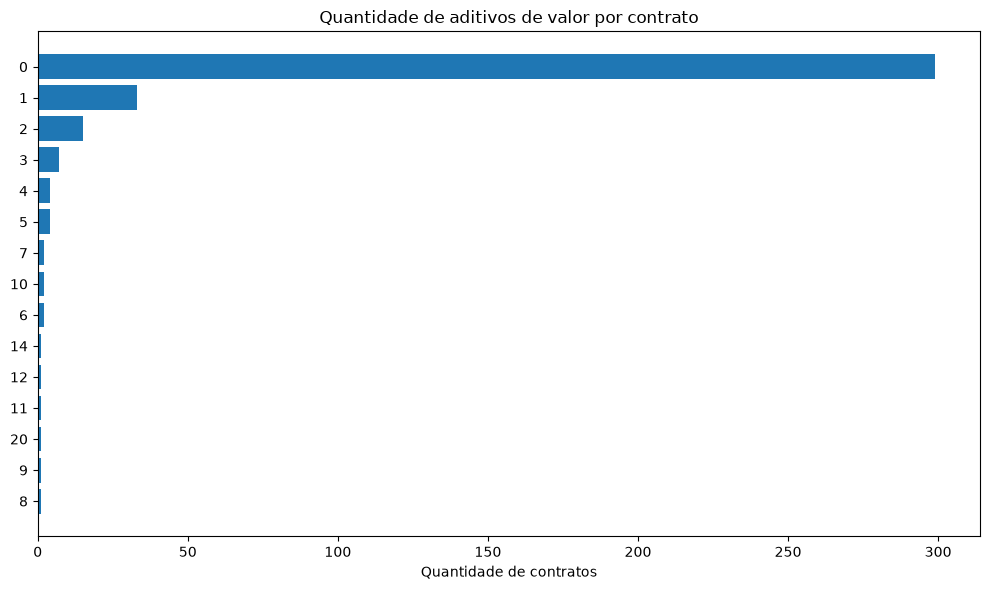

In [ ]:
if "qtd_aditivos_valor_acumulado" in latest.columns:
    plot_counts(
        latest["qtd_aditivos_valor_acumulado"].fillna(0).astype(int),
        "Quantidade de aditivos de valor por contrato",
        top=15,
    )


## 8. Evolução temporal

In [ ]:
data_minima = pd.Timestamp("2014-01-01")  # ajuste ao histórico esperado
data_maxima = pd.Timestamp.today().normalize()

datas_validas = df["data_corte"].between(data_minima, data_maxima)
df_temporal = df.loc[datas_validas].copy()

print("Registros fora do intervalo:", int((~datas_validas).sum()))
display(df.loc[~datas_validas, ["id_contrato", "data_corte"]])

Registros fora do intervalo: 9


,id_contrato,data_corte
1600,100,8202-08-11
1709,105,23-02-26
3265,167,202-04-07
3357,167,2502-05-20
4201,212,24-12-06
5340,246,2027-07-25
6612,292,204-05-24
7011,327,25-12-02
7643,402,2026-11-16


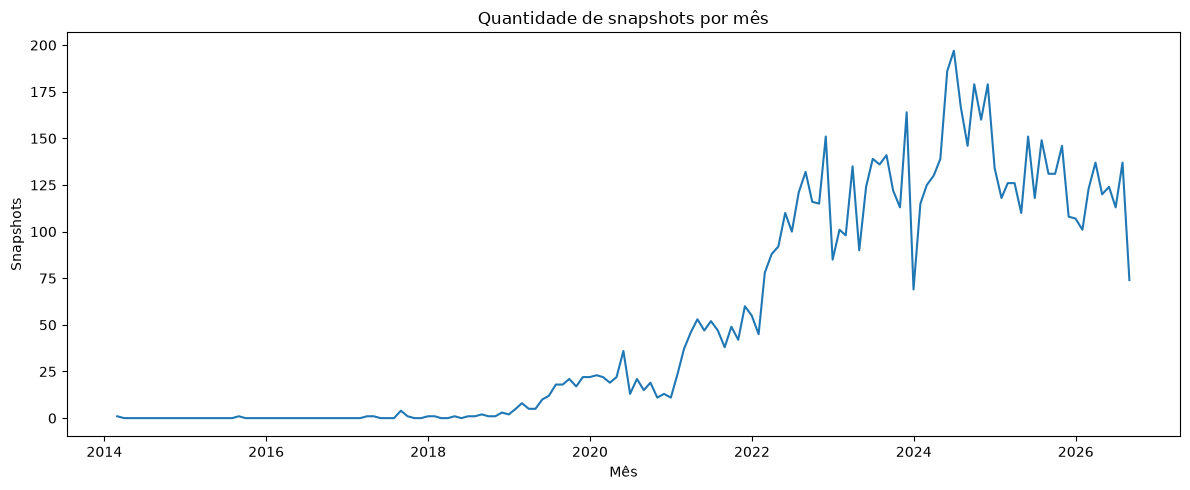

In [ ]:
snapshots_month = (
    df_temporal.set_index("data_corte")
    .resample("ME")
    .size()
)

plt.figure(figsize=(12, 5))
plt.plot(snapshots_month.index, snapshots_month.values)
plt.title("Quantidade de snapshots por mês")
plt.xlabel("Mês")
plt.ylabel("Snapshots")
plt.tight_layout()
plt.show()


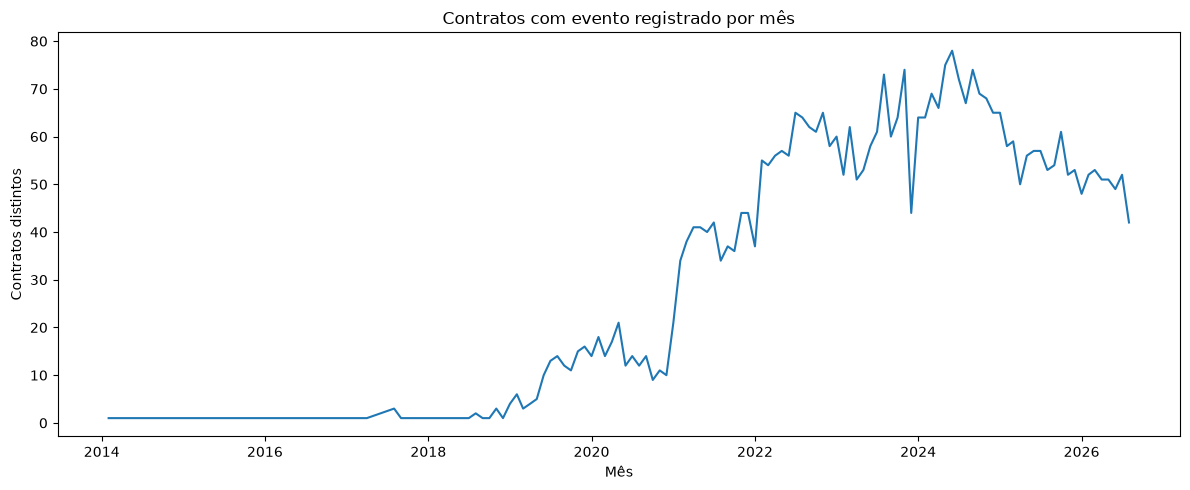

In [ ]:
contracts_month = (
    df_temporal.assign(
        mes=lambda data: data["data_corte"].dt.to_period("M").dt.to_timestamp()
    )
    .groupby("mes")["id_contrato"]
    .nunique()
)

plt.figure(figsize=(12, 5))
plt.plot(contracts_month.index, contracts_month.values)
plt.title("Contratos com evento registrado por mês")
plt.xlabel("Mês")
plt.ylabel("Contratos distintos")
plt.tight_layout()
plt.show()


## 9. Relações entre variáveis numéricas

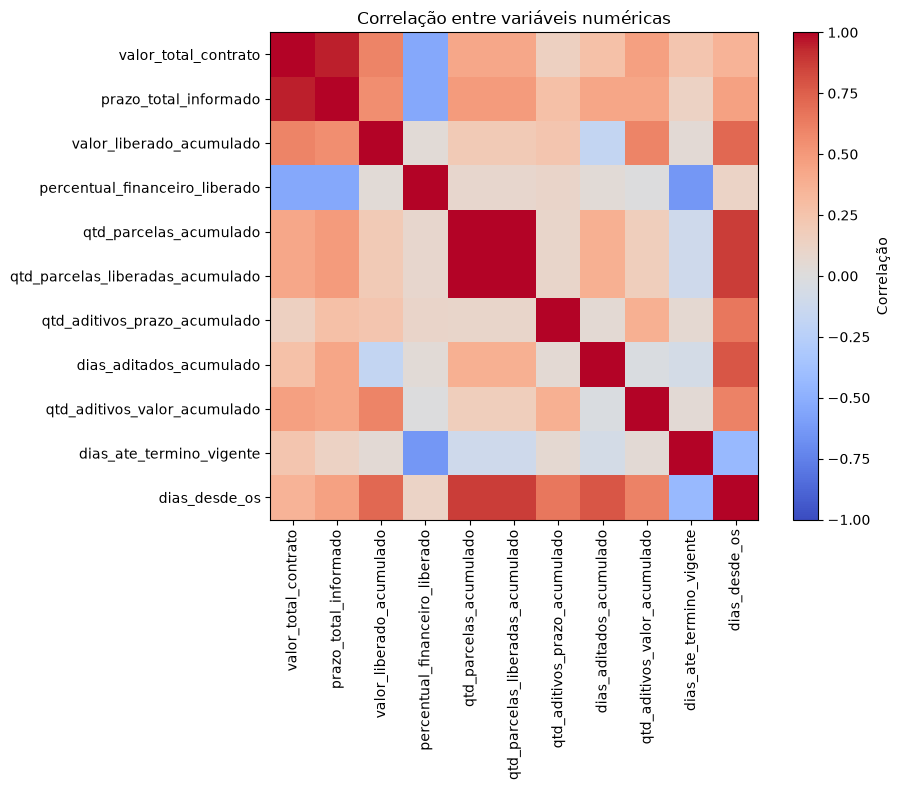

In [ ]:
candidate_numeric = [
    "valor_total_contrato", "prazo_total_informado", "valor_liberado_acumulado",
    "percentual_financeiro_liberado", "qtd_parcelas_acumulado",
    "qtd_parcelas_liberadas_acumulado", "qtd_aditivos_prazo_acumulado",
    "dias_aditados_acumulado", "qtd_aditivos_valor_acumulado",
    "dias_ate_termino_vigente", "dias_desde_os"
]
numeric_columns = [column for column in candidate_numeric if column in latest.columns]
correlation = latest[numeric_columns].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation.columns)))
ax.set_xticklabels(correlation.columns, rotation=90)
ax.set_yticks(range(len(correlation.index)))
ax.set_yticklabels(correlation.index)
fig.colorbar(image, ax=ax, label="Correlação")
ax.set_title("Correlação entre variáveis numéricas")
plt.tight_layout()
plt.show()


## 10. Registros suspeitos

In [ ]:
suspeitos = latest[
    latest.get("flag_percentual_financeiro_suspeito", pd.Series(0, index=latest.index)).eq(1)
].copy()

print("Contratos com percentual financeiro suspeito:", len(suspeitos))
suspeitos[[
    column for column in [
        "id_contrato", "numero_contrato", "valor_total_contrato",
        "valor_liberado_acumulado", "percentual_financeiro_liberado"
    ] if column in suspeitos.columns
]].head(20)


Contratos com percentual financeiro suspeito: 1


,id_contrato,numero_contrato,valor_total_contrato,valor_liberado_acumulado,percentual_financeiro_liberado
298,49,110/2019,"135,821.26","462,275.23",3.40


In [ ]:
datas_futuras = df[df["data_corte"] > pd.Timestamp.today().normalize()].copy()
print("Snapshots com data de corte futura:", len(datas_futuras))
datas_futuras[["id_contrato", "data_corte"]].head(20)


Snapshots com data de corte futura: 4


,id_contrato,data_corte
1600,100,8202-08-11
3357,167,2502-05-20
5340,246,2027-07-25
7643,402,2026-11-16


## 11. Resumo final

In [ ]:
resumo_final = pd.DataFrame({
    "Indicador": [
        "Snapshots",
        "Contratos distintos",
        "Data de corte mínima",
        "Data de corte máxima",
        "Contratos concluídos",
        "Contratos com aditivo de prazo",
        "Contratos com aditivo de valor",
        "Contratos com percentual financeiro suspeito",
    ],
    "Valor": [
        len(df),
        df["id_contrato"].nunique(),
        df["data_corte"].min(),
        df["data_corte"].max(),
        int(latest["status_contrato"].astype("string").str.upper().eq("CONCLUÍDO").sum()),
        int(latest.get("qtd_aditivos_prazo_acumulado", pd.Series(0, index=latest.index)).fillna(0).gt(0).sum()),
        int(latest.get("qtd_aditivos_valor_acumulado", pd.Series(0, index=latest.index)).fillna(0).gt(0).sum()),
        len(suspeitos),
    ],
})
resumo_final


,Indicador,Valor
0,Snapshots,7942
1,Contratos distintos,374
2,Data de corte mínima,0023-02-26 00:00:00
3,Data de corte máxima,8202-08-11 00:00:00
4,Contratos concluídos,49
5,Contratos com aditivo de prazo,107
6,Contratos com aditivo de valor,75
7,Contratos com percentual financeiro suspeito,1


## Leitura recomendada

- Use `df` para analisar todos os snapshots.
- Use `latest` para comparar contratos sem contar o mesmo contrato várias vezes.
- Colunas com muitos nulos devem ser avaliadas antes da modelagem.
- Percentuais financeiros acima de 1,5 permanecem sinalizados, sem exclusão automática.
